# Hospital Analytics: SQL and Python on a Synthetic EHR Dataset

**Business question:** where should a hospital put its care-management effort, and how do you tell a
number you can act on from a number that only looks like a finding?

**Stakeholder:** hospital finance and operations leadership deciding where to place care-management
staff and which payer relationships to prioritise.

**Headline finding:** cost is extremely concentrated, the top 10% of encounters carry **66.5%** of
billed charges, and the dataset's most dramatic number, a **$70.4M** billed-vs-covered gap, is an
artifact of how the synthetic data was generated rather than a revenue-cycle finding.

The sections below follow the findings in `README.md`, in the same order.

### Contents

1. [The data](#1-the-data)
2. [Finding 1: care is overwhelmingly ambulatory](#2-finding-1-care-is-overwhelmingly-ambulatory)
3. [Finding 2: cost is extremely concentrated](#3-finding-2-cost-is-extremely-concentrated)
4. [Finding 3: two payers carry most of the money](#4-finding-3-two-payers-carry-most-of-the-money)
5. [Finding 4: inpatient operations](#5-finding-4-inpatient-operations)
6. [Finding 5: the $70.4M gap is an artifact](#6-finding-5-the-704m-gap-is-an-artifact)
7. [Finding 6: volume over time](#7-finding-6-volume-over-time)
8. [The executive summary](#8-the-executive-summary)
9. [Limitations and next steps](#9-limitations-and-next-steps)

## 1. The data

Everything below runs against a six-table SQLite database built from the Synthea synthetic patient
records (Massachusetts General Hospital sample) by `scripts/build_db.py`. The notebook connects
**read-only**, so nothing here can alter the data.

In [1]:
%matplotlib inline

import pathlib
import sqlite3
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
FIG, OUT = ROOT / "figures", ROOT / "outputs"
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

DB = ROOT / "data" / "hospital.db"
if not DB.exists():                     # a fresh clone has no database yet
    print("building data/hospital.db from data/raw ...")
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_db.py")], check=True)

db = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)      # read-only by construction
q = lambda sql: pd.read_sql_query(sql, db)

pd.set_option("display.width", 200)
sns.set_theme(style="white", context="talk")              # clean background, no gridlines


def strip_spines(ax):
    """Drop the axes border. The bars carry the chart; the box adds nothing."""
    for spine in ax.spines.values():
        spine.set_visible(False)


def strip_xaxis(ax):
    """Drop the x scale. Each bar carries its own value label instead."""
    ax.set_xticks([])
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=0)


def label_bars(ax, bars, values, fmt="{:.1f}%", pad=0.6):
    for bar, value in zip(bars, values):
        ax.text(bar.get_width() + pad, bar.get_y() + bar.get_height() / 2,
                fmt.format(value), va="center", fontsize=9)


print(f"connected read-only: {DB.relative_to(ROOT)}")

connected read-only: data/hospital.db


In [2]:
inventory = q("""
SELECT 'encounters' AS table_name, COUNT(*) AS rows FROM encounters
UNION ALL SELECT 'procedures',      COUNT(*) FROM procedures
UNION ALL SELECT 'patients',        COUNT(*) FROM patients
UNION ALL SELECT 'payers',          COUNT(*) FROM payers
UNION ALL SELECT 'organizations',   COUNT(*) FROM organizations
UNION ALL SELECT 'data_dictionary', COUNT(*) FROM data_dictionary
""")

span = q("""
SELECT MIN(START) AS first_encounter, MAX(START) AS last_encounter,
       COUNT(DISTINCT PATIENT) AS patients, COUNT(DISTINCT PAYER) AS payers
FROM encounters
""").iloc[0]

encounters = int(inventory.loc[inventory.table_name == "encounters", "rows"].iloc[0])
print(f"{encounters:,} encounters, {span.patients} patients, {span.payers} payers, "
      f"{span.first_encounter[:10]} to {span.last_encounter[:10]}")
print("grain: one row per visit in encounters, one row per billed line item in procedures")
inventory

27,891 encounters, 974 patients, 10 payers, 2011-01-02 to 2022-02-05
grain: one row per visit in encounters, one row per billed line item in procedures


,table_name,rows
0,encounters,27891
1,procedures,47701
2,patients,974
3,payers,10
4,organizations,1
5,data_dictionary,65


In [3]:
panel = q("""
SELECT CASE WHEN age < 18 THEN '0-17'
            WHEN age < 40 THEN '18-39'
            WHEN age < 65 THEN '40-64'
            ELSE '65+' END AS age_band,
       COUNT(*) AS patients
FROM (SELECT (julianday('2022-01-01') - julianday(BIRTHDATE)) / 365.25 AS age FROM patients)
GROUP BY age_band
ORDER BY patients DESC
""")

deaths = int(q("SELECT COUNT(*) AS d FROM patients WHERE DEATHDATE IS NOT NULL").d[0])
age_65 = int(panel.loc[panel.age_band == "65+", "patients"].iloc[0])
print(f"{age_65} of {span.patients} patients are 65 or older; {deaths} have a recorded death date.")
print("age is taken at a fixed 2022-01-01 snapshot, so it does not drift as time passes")
panel

576 of 974 patients are 65 or older; 154 have a recorded death date.
age is taken at a fixed 2022-01-01 snapshot, so it does not drift as time passes


,age_band,patients
0,65+,576
1,40-64,303
2,18-39,95


The grain matters more than the row counts. `encounters` mixes a 14-minute wellness check with a
week-long admission, so nothing downstream is an average across all of it without saying so.

## 2. Finding 1: care is overwhelmingly ambulatory

Before averaging anything: what is actually in the table? This is the check that sets the scope for
every metric that follows.

In [4]:
mix = q("""
SELECT ENCOUNTERCLASS AS setting,
       COUNT(*) AS encounters,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM encounters), 1) AS pct_of_all,
       ROUND(AVG(julianday(STOP) - julianday(START)), 3) AS avg_days
FROM encounters
GROUP BY ENCOUNTERCLASS
ORDER BY encounters DESC
""")

inpatient = int(mix.loc[mix.setting == "inpatient", "encounters"].iloc[0])
same_day = int(mix.loc[mix.setting != "inpatient", "encounters"].sum())
print(f"{same_day / encounters:.1%} of encounters are same-day contact. "
      f"Inpatient is {inpatient:,} of {encounters:,} ({inpatient / encounters:.1%}).")
mix

95.9% of encounters are same-day contact. Inpatient is 1,135 of 27,891 (4.1%).


,setting,encounters,pct_of_all,avg_days
0,ambulatory,12537,44.9,0.395
1,outpatient,6300,22.6,0.245
2,urgentcare,3666,13.1,0.010
3,emergency,2322,8.3,0.064
4,wellness,1931,6.9,0.010
5,inpatient,1135,4.1,1.535


**Reading the chart (the tables above).** Six settings of care in one table: the four ambulatory rows
  are 95.9% of the volume, and inpatient is 4.1%. The population is named before any average is taken,
  which is why every measure below carries its scope with it.
- "Length of stay" and "cost per visit" describe the **1,135 inpatient rows**, not the table.
- A metric that does not name its population is quoting a number that mixes a check-up with an
  admission, which is where most misleading healthcare averages come from.
- The scope decision is therefore made once, here, and every metric below states its population.

## 3. Finding 2: cost is extremely concentrated

Where would care-management effort actually pay off? `NTILE(10)` splits the encounters into ten
equal buckets ordered by cost, which turns "it is concentrated" into a number someone can act on.

the most expensive 10% of encounters carry 66.5% of all billed cost; the top 20% carry 89.8%
mean encounter $3,651 against a median of $279: the average is the tail, not the typical visit


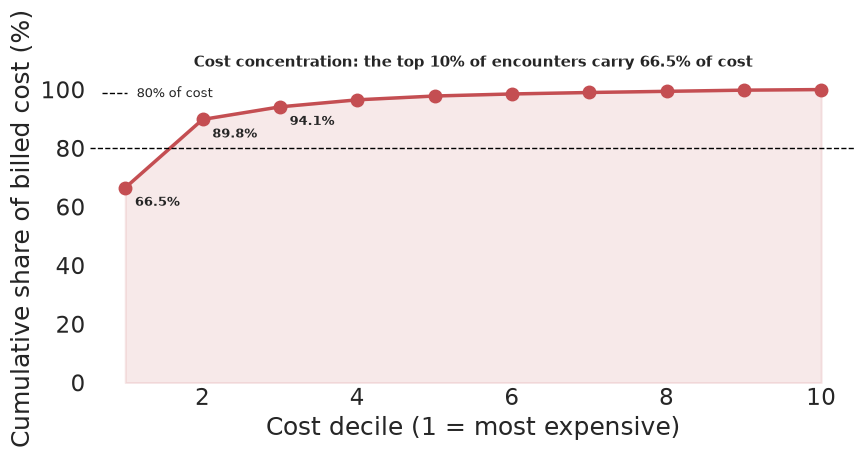

In [5]:
pareto = q("""
WITH billed AS (
    SELECT TOTAL_CLAIM_COST AS value FROM encounters WHERE TOTAL_CLAIM_COST > 0
),
ranked AS (
    SELECT value, NTILE(10) OVER (ORDER BY value DESC) AS decile FROM billed
)
SELECT decile,
       COUNT(*)  AS encounters,
       ROUND(SUM(value), 0) AS billed,
       ROUND(100.0 * SUM(value) / (SELECT SUM(value) FROM billed), 1) AS pct_share,
       ROUND(SUM(SUM(value)) OVER (ORDER BY decile)
             / (SELECT SUM(value) FROM billed) * 100, 1) AS cumulative_pct
FROM ranked
GROUP BY decile
ORDER BY decile
""")

print(f"the most expensive 10% of encounters carry {pareto.pct_share[0]}% of all billed cost; "
      f"the top 20% carry {pareto.cumulative_pct[1]}%")

typical = q("""
WITH v AS (SELECT TOTAL_CLAIM_COST AS c FROM encounters WHERE TOTAL_CLAIM_COST > 0),
     r AS (SELECT c, ROW_NUMBER() OVER (ORDER BY c) AS rn, COUNT(*) OVER () AS n FROM v)
SELECT ROUND(AVG(c), 0) AS mean_cost,
       ROUND((SELECT c FROM r WHERE rn = CAST(n * 0.5 AS INT)), 0) AS median_cost
FROM v
""").iloc[0]
print(f"mean encounter ${typical.mean_cost:,.0f} against a median of ${typical.median_cost:,.0f}: "
      f"the average is the tail, not the typical visit")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(pareto.decile, pareto.cumulative_pct, marker="o", lw=2.5, color="#C44E52")
ax.fill_between(pareto.decile, 0, pareto.cumulative_pct, alpha=0.12, color="#C44E52")
ax.axhline(80, ls="--", color="black", lw=1, label="80% of cost")
for _, row in pareto.head(3).iterrows():
    ax.annotate(f"{row.cumulative_pct}%", (row.decile, row.cumulative_pct),
                textcoords="offset points", xytext=(7, -13), fontsize=9, weight="bold")
ax.set_xlabel("Cost decile (1 = most expensive)")
ax.set_ylabel("Cumulative share of billed cost (%)")
ax.set_ylim(0, 105)
ax.set_title(f"Cost concentration: the top 10% of encounters carry {pareto.pct_share[0]}% of cost",
             fontsize=11, weight="bold")
ax.legend(fontsize=9, frameon=False)
strip_spines(ax)
ax.tick_params(axis="both", length=0)
fig.tight_layout()
fig.savefig(FIG / "01_cost_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart.** The curve reaches 66.5% at its first marker and crosses the 80% line partway
  through decile 2; decile 3 takes it to 94.1%, so the bottom seven deciles share the remaining 5.9%.
  It is a cumulative curve rather than ten bars because the decision is about how much spend a target
  captures, not about the individual deciles.
- **66.5%** of billed cost sits in the most expensive tenth of encounters and **89.8%** in the top
  fifth, from 27,891 encounters that bill $3,651 on average but only **$279** at the median.
- A care-management programme aimed at the top decile is aimed at two thirds of the spend, which is
  the finding a staffing decision actually turns on.
- Concentration this steep is normal for healthcare cost, which is exactly why the decile has to be
  defined before the number is quoted.

## 4. Finding 3: two payers carry most of the money

Who is the counterparty? The payer joined in adds the name to the cost, and the same query carries a
running share so the "how many payers do we actually depend on" question has a number.

10 payers, but the top two carry 72.8% of billed charges (NO_INSURANCE alone is 48.5%)


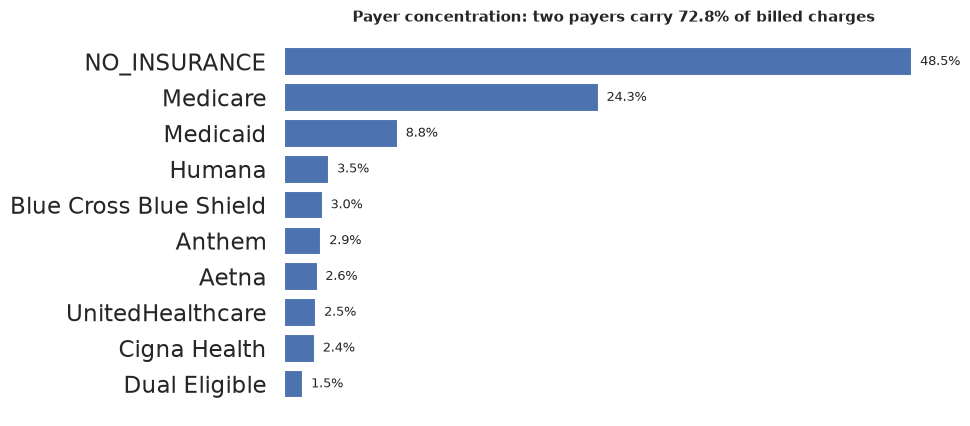

In [6]:
payer = q("""
WITH by_payer AS (
    SELECT py.NAME AS payer, COUNT(*) AS encounters, SUM(e.TOTAL_CLAIM_COST) AS billed,
           ROUND(100.0 * SUM(e.PAYER_COVERAGE) / NULLIF(SUM(e.TOTAL_CLAIM_COST), 0), 1) AS pct_covered
    FROM encounters e
    JOIN payers py ON e.PAYER = py.Id
    WHERE e.TOTAL_CLAIM_COST > 0
    GROUP BY py.NAME
)
SELECT payer, encounters, ROUND(billed, 0) AS billed,
       ROUND(100.0 * billed / (SELECT SUM(billed) FROM by_payer), 1) AS pct_share,
       ROUND(SUM(100.0 * billed / (SELECT SUM(billed) FROM by_payer))
             OVER (ORDER BY billed DESC), 1) AS cumulative_pct,
       pct_covered
FROM by_payer
ORDER BY billed DESC
""")

print(f"{len(payer)} payers, but the top two carry {payer.cumulative_pct[1]}% of billed charges "
      f"({payer.payer[0]} alone is {payer.pct_share[0]}%)")

fig, ax = plt.subplots(figsize=(10, 4.6))
d = payer.sort_values("billed")
bars = ax.barh(d.payer, d.pct_share, color="#4C72B0")
label_bars(ax, bars, d.pct_share)
ax.set_title(f"Payer concentration: two payers carry {payer.cumulative_pct[1]}% of billed charges",
             fontsize=11, weight="bold")
strip_spines(ax)
strip_xaxis(ax)
fig.tight_layout()
fig.savefig(FIG / "02_payer_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart.** Ten bars, but only two carry material width: everything below Medicaid (8.8%)
  is under 3.5%, and the eight smallest payers together are 27.2%. The largest single counterparty is
  `NO_INSURANCE` at 48.5%, which is the thread Finding 5 picks up.
- Contract and relationship planning here is a **two-payer conversation**, not a payer-mix exercise.
- Note the `pct_covered` column: it is already pointing at the artifact in Finding 5, where two payers
  come in at 0% and the rest at 36% or higher.
- Payers with very few inpatient stays are excluded from length-of-stay comparisons, because an
  average over three stays is not a measurement.

## 5. Finding 4: inpatient operations

Two operational measures, both scoped to the 1,135 inpatient stays: how long patients stay, and how
often they come back. Both are examples of a metric that is only as good as its definition.

In [7]:
alos = q("""
WITH stays AS (
    SELECT julianday(STOP) - julianday(START) AS los
    FROM encounters
    WHERE ENCOUNTERCLASS = 'inpatient' AND START IS NOT NULL AND STOP IS NOT NULL
),
ranked AS (SELECT los, ROW_NUMBER() OVER (ORDER BY los) AS rn, COUNT(*) OVER () AS n FROM stays)
SELECT (SELECT COUNT(*) FROM stays)                                        AS inpatient_stays,
       ROUND((SELECT AVG(los) FROM stays), 2)                              AS mean_los,
       ROUND((SELECT los FROM ranked WHERE rn = CAST(n * 0.50 AS INT)), 2) AS median_los,
       ROUND((SELECT MAX(los) FROM stays), 1)                              AS max_los,
       (SELECT SUM(CASE WHEN los = 1.0 THEN 1 ELSE 0 END) FROM stays)      AS exactly_one_day,
       ROUND(100.0 * (SELECT SUM(CASE WHEN los = 1.0 THEN 1 ELSE 0 END) FROM stays)
                   / (SELECT COUNT(*) FROM stays), 1)                      AS pct_exactly_one_day
""").iloc[0]

print(f"{alos.inpatient_stays:,} stays. Mean {alos.mean_los} days, median {alos.median_los} days, "
      f"longest {alos.max_los} days.")
print(f"{alos.pct_exactly_one_day}% are exactly one day, so the mean is not the representative stay.")
pd.DataFrame([alos])

1,135.0 stays. Mean 1.54 days, median 1.0 days, longest 343.8 days.
94.9% are exactly one day, so the mean is not the representative stay.


,inpatient_stays,mean_los,median_los,max_los,exactly_one_day,pct_exactly_one_day
0,1135.0,1.54,1.0,343.8,1077.0,94.9


same table, three defensible-sounding answers: A 25.78%, B 15.66%, C 36.0%
report definition C: 36.0% of inpatient stays follow a discharge within 30 days


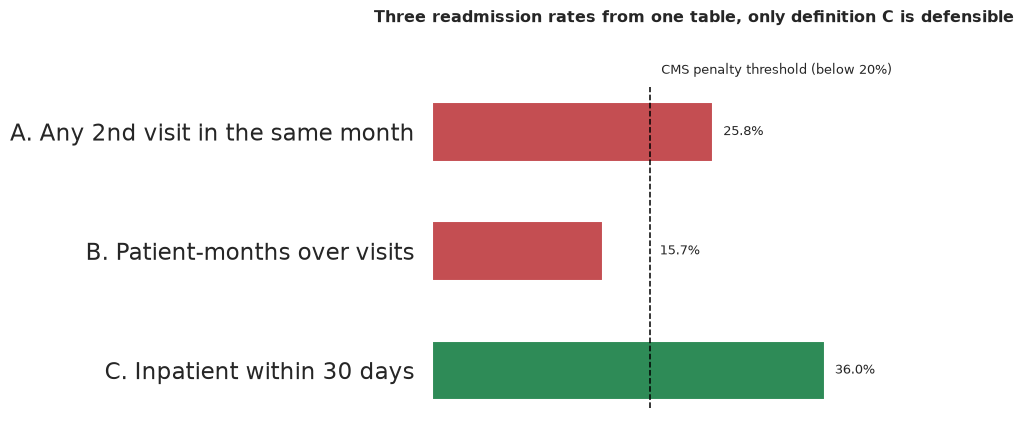

In [8]:
# The same table, read three ways. Only one definition matches how readmission is
# actually operationalised, and all three are computed with a single query each.
defs = pd.DataFrame({
    "definition": [
        "A. Any 2nd encounter in the same month",
        "B. Patient-months over visits (mixed units)",
        "C. Inpatient to inpatient within 30 days",
    ],
    "rate_pct": [
        float(q("""
            WITH monthly_visits AS (
                SELECT PATIENT, DATE(START, 'start of month') AS month, COUNT(*) AS visits_in_month
                FROM encounters WHERE START IS NOT NULL AND TOTAL_CLAIM_COST > 0
                GROUP BY PATIENT, month)
            SELECT ROUND(100.0 * SUM(CASE WHEN visits_in_month > 1 THEN 1 ELSE 0 END)
                       / COUNT(*), 2) AS rate_pct FROM monthly_visits
        """).rate_pct[0]),
        float(q("""
            WITH monthly_visits AS (
                SELECT PATIENT, DATE(START, 'start of month') AS month, COUNT(*) AS visits_in_month
                FROM encounters WHERE START IS NOT NULL AND TOTAL_CLAIM_COST > 0
                GROUP BY PATIENT, month)
            SELECT ROUND(100.0 * SUM(CASE WHEN visits_in_month > 1 THEN 1 ELSE 0 END)
                       / SUM(visits_in_month), 2) AS rate_pct FROM monthly_visits
        """).rate_pct[0]),
        float(q("""
            WITH inpatient_stays AS (
                SELECT PATIENT, START, STOP,
                       LAG(STOP) OVER (PARTITION BY PATIENT ORDER BY START) AS prev_discharge
                FROM encounters
                WHERE ENCOUNTERCLASS = 'inpatient' AND START IS NOT NULL AND STOP IS NOT NULL)
            SELECT ROUND(100.0 * SUM(CASE WHEN prev_discharge IS NOT NULL
                       AND julianday(START) - julianday(prev_discharge) BETWEEN 0 AND 30
                       THEN 1 ELSE 0 END) / COUNT(*), 1) AS rate_pct FROM inpatient_stays
        """).rate_pct[0]),
    ],
    "defensible": ["No", "No", "Yes"],
    "why": ["Measures visit frequency; resets at the month boundary",
            "Numerator and denominator count different units",
            "Matches how readmission is defined operationally"],
    "short": ["A. Any 2nd visit in the same month",
              "B. Patient-months over visits",
              "C. Inpatient within 30 days"],
})
readmit_c = defs.rate_pct[2]
print("same table, three defensible-sounding answers:", ", ".join(
    f"{r.definition[0]} {r.rate_pct}%" for r in defs.itertuples()))
print(f"report definition C: {readmit_c}% of inpatient stays follow a discharge within 30 days")

fig, ax = plt.subplots(figsize=(10, 4.8))
d = defs.iloc[::-1]                                   # A at the top, read downwards
bars = ax.barh(d.short, d.rate_pct, height=0.5, color=["#2E8B57", "#C44E52", "#C44E52"])
# B's value label would sit under the threshold line, so it is pushed clear of it.
for bar, value, pad in zip(bars, d.rate_pct, [0.9, 5.2, 0.9]):
    ax.text(bar.get_width() + pad, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%",
            va="center", fontsize=9)
# the line marks the threshold across the bars, not across empty space
ax.axvline(20, color="black", ls="--", lw=1.1, ymin=0.07, ymax=0.86)
ax.annotate("CMS penalty threshold (below 20%)", xy=(21, 2.52), fontsize=9, va="center")
ax.set_xlim(0, 48)
ax.set_ylim(-0.55, 2.85)
ax.set_title("Three readmission rates from one table, only definition C is defensible",
             fontsize=11.5, weight="bold")
strip_spines(ax)
strip_xaxis(ax)
fig.tight_layout()
fig.savefig(FIG / "03_readmission_definitions.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart.** Two of the three bars clear the 20% CMS penalty threshold and one does not, so
  the definition changes the compliance answer, not just the number: 15.7% says the hospital is fine,
  36.0% says it is not.
- **Report the median, not the mean**: 94.9% of stays are exactly one day, and the 1.54-day mean is
  pulled by two stays over 30 days (the longest is 343.75 days).
- The definition is the deliverable. Three numbers came out of one table, and the difference is not
  arithmetic, it is what each one measures.
- `LAG()` over the patient's ordered history is the reusable technique: the same window function
  answers "time to next event" for churn, reorder interval, or readmission.

## 6. Finding 5: the $70.4M gap is an artifact

The dataset's most dramatic number. The arithmetic is correct and the finding is still not usable,
and the difference between those two statements is the point of this section.

$101.5M billed, $31.1M covered: a $70.4M gap at 30.6% coverage
by setting it runs from 18.5% to 63.8%
all settings: 52.0% of procedures carry some coverage (the 30.6% gap above is dollar-weighted, a different measure)


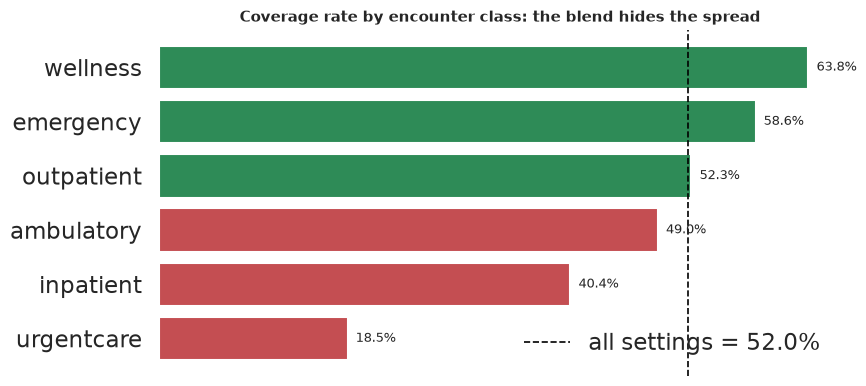

In [9]:
gap = q("""
SELECT ROUND(SUM(TOTAL_CLAIM_COST), 0) AS total_billed,
       ROUND(SUM(PAYER_COVERAGE), 0) AS total_covered,
       ROUND(SUM(TOTAL_CLAIM_COST) - SUM(PAYER_COVERAGE), 0) AS revenue_gap,
       ROUND(100.0 * SUM(PAYER_COVERAGE) / SUM(TOTAL_CLAIM_COST), 1) AS pct_covered
FROM encounters WHERE TOTAL_CLAIM_COST > 0
""").iloc[0]

by_class = q("""
SELECT e.ENCOUNTERCLASS AS setting, COUNT(*) AS procedures,
       ROUND(100.0 * SUM(CASE WHEN e.PAYER_COVERAGE > 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS coverage_pct
FROM procedures p
JOIN encounters e ON p.ENCOUNTER = e.Id
GROUP BY e.ENCOUNTERCLASS
ORDER BY coverage_pct DESC
""")

print(f"${gap.total_billed/1e6:.1f}M billed, ${gap.total_covered/1e6:.1f}M covered: "
      f"a ${gap.revenue_gap/1e6:.1f}M gap at {gap.pct_covered}% coverage")
print(f"by setting it runs from {by_class.coverage_pct.min()}% to {by_class.coverage_pct.max()}%")

all_settings = q("""
SELECT ROUND(100.0 * SUM(CASE WHEN e.PAYER_COVERAGE > 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct
FROM procedures p
JOIN encounters e ON p.ENCOUNTER = e.Id
""").pct[0]
print(f"all settings: {all_settings}% of procedures carry some coverage (the {gap.pct_covered}% gap above "
      f"is dollar-weighted, a different measure)")

fig, ax = plt.subplots(figsize=(9, 4.2))
d = by_class.sort_values("coverage_pct")
bars = ax.barh(d.setting, d.coverage_pct,
               color=["#C44E52" if v < all_settings else "#2E8B57" for v in d.coverage_pct])
label_bars(ax, bars, d.coverage_pct, pad=0.8)
# like for like: the bars are shares of procedures, so the reference line is too
ax.axvline(all_settings, color="black", ls="--", lw=1.2, label=f"all settings = {all_settings}%")
ax.set_title("Coverage rate by encounter class: the blend hides the spread", fontsize=11, weight="bold")
ax.legend(loc="lower right", frameon=False)
strip_spines(ax)
strip_xaxis(ax)
fig.tight_layout()
fig.savefig(FIG / "04_coverage_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

coverage is 0 wherever the encounter was assigned to: UnitedHealthcare, Humana, Aetna, Cigna Health, Anthem, NO_INSURANCE
and never 0 for: Medicaid, Medicare


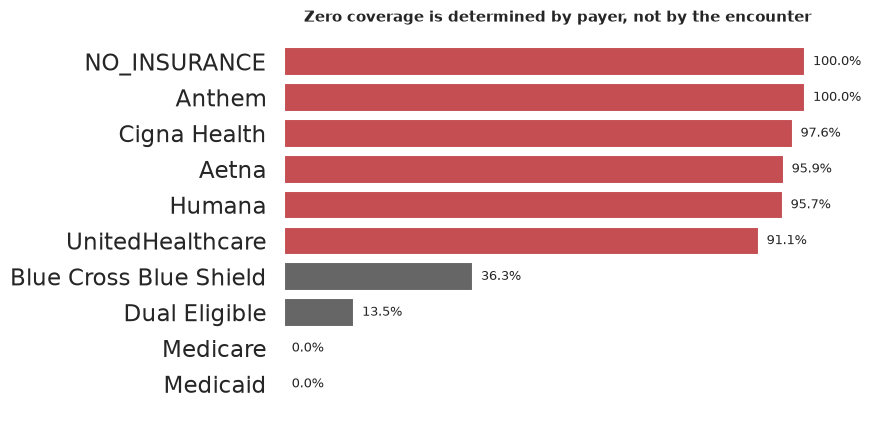

In [10]:
# The test: is zero coverage explained by the encounter, or by the payer it was assigned to?
by_payer = q("""
SELECT py.NAME AS payer, COUNT(*) AS encounters,
       ROUND(100.0 * SUM(CASE WHEN e.PAYER_COVERAGE = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_zero
FROM encounters e
JOIN payers py ON e.PAYER = py.Id
WHERE e.TOTAL_CLAIM_COST > 0
GROUP BY py.NAME
ORDER BY pct_zero
""")

switched = by_payer[(by_payer.pct_zero > 90) | (by_payer.pct_zero == 0)]
print("coverage is 0 wherever the encounter was assigned to:",
      ", ".join(switched.loc[switched.pct_zero > 90, "payer"]))
print("and never 0 for:", ", ".join(switched.loc[switched.pct_zero == 0, "payer"]))

fig, ax = plt.subplots(figsize=(9, 4.6))
d = by_payer.sort_values("pct_zero")
bars = ax.barh(d.payer, d.pct_zero,
               color=["#C44E52" if v > 90 else ("#666666" if v > 0 else "#2E8B57") for v in d.pct_zero])
label_bars(ax, bars, d.pct_zero, pad=1.5)
ax.set_title("Zero coverage is determined by payer, not by the encounter", fontsize=11, weight="bold")
strip_spines(ax)
strip_xaxis(ax)
fig.tight_layout()
fig.savefig(FIG / "05_coverage_artifact.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart.** The rates are shares of procedures with any coverage, so the reference line is
  the all-settings rate of 52.0%, not the dollar-weighted 30.6%: wellness and emergency sit above it,
  ambulatory, inpatient and urgentcare below. Comparing the two measures is the error this section is
  about.
- Coverage is a **switch, not a distribution**: every Medicaid and Medicare encounter is covered,
  every `NO_INSURANCE` and Anthem encounter is not, and Anthem's 703 encounters contain no partial
  payment at all. A real payer mix produces a distribution.
- So the $70.4M measures **which insurer the generator assigned**, not payment behaviour. Correct
  arithmetic, invalid finding.
- The figures stay in the notebook, labelled, because they are the clearest example of the difference
  between a number that is *computed* and a number that is *trustworthy*.
- The gap is nearly all one population: `NO_INSURANCE` is **70.0%** of the $70.4M, and even Medicare,
  which is never zero, contributes 7.7% because coverage is partial whenever it is nonzero.

## 7. Finding 6: volume over time

Volume is the denominator of everything above, so it is worth knowing it is stable. 2022 is excluded:
the extract stops on 5 February 2022, and a partial year on the same axis reads as a collapse.

after the panel fills in 2014 (3,885), volume holds at 2,228 to 2,519 encounters a year through 2020; 2021 runs 3,530 and the extract ends on 5 Feb 2022


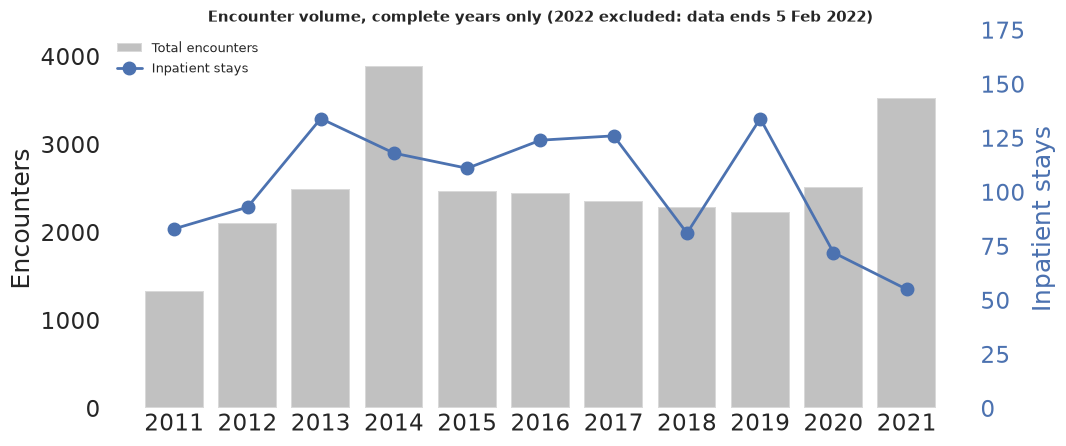

In [11]:
trend = q("""
SELECT strftime('%Y', START) AS year, COUNT(*) AS encounters,
       SUM(CASE WHEN ENCOUNTERCLASS = 'inpatient' THEN 1 ELSE 0 END) AS inpatient
FROM encounters WHERE START IS NOT NULL
GROUP BY year ORDER BY year
""")
trend["is_partial"] = trend.year == "2022"
full = trend[~trend.is_partial]

plateau = full[(full.year.astype(int) >= 2015) & (full.year.astype(int) <= 2020)]
y2021 = int(full.loc[full.year == "2021", "encounters"].iloc[0])
print(f"after the panel fills in 2014 ({full.encounters.max():,}), volume holds at "
      f"{plateau.encounters.min():,} to {plateau.encounters.max():,} encounters a year through 2020; "
      f"2021 runs {y2021:,} and the extract ends on 5 Feb 2022")

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(full.year, full.encounters, color="#666666", alpha=0.40, label="Total encounters")
ax.set_ylabel("Encounters")
ax.set_ylim(0, 4300)                      # headroom, so the legend clears the bars

# Inpatient is 4% of total volume. It gets its own axis on the right rather than being
# multiplied by a scaling factor to show up on this one.
ax2 = ax.twinx()
ax2.plot(full.year, full.inpatient, color="#4C72B0", marker="o", lw=2, label="Inpatient stays")
ax2.set_ylabel("Inpatient stays", color="#4C72B0")
ax2.tick_params(axis="y", colors="#4C72B0")
ax2.set_ylim(0, 175)

ax.set_title("Encounter volume, complete years only (2022 excluded: data ends 5 Feb 2022)",
             fontsize=11, weight="bold")
handles, labels = ax.get_legend_handles_labels()
more_handles, more_labels = ax2.get_legend_handles_labels()
ax.legend(handles + more_handles, labels + more_labels, loc="upper left", frameon=False, fontsize=9)

strip_spines(ax)
strip_spines(ax2)
ax.tick_params(axis="both", length=0)
ax2.tick_params(axis="both", length=0)
fig.tight_layout()
fig.savefig(FIG / "06_volume_trend.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart.** The bars are flat after the 2014 ramp, and the blue line drifts down from 134
  inpatient stays in 2019 to 55 in 2021 while total encounters rise, so the 2021 rise is ambulatory
  volume rather than admissions.
- Volume is flat through the plateau years, so the concentration findings are not an artifact of a
  growing denominator.
- 2011 to 2014 is the simulated patient panel filling up, not a demand change, which is why trends are
  read from 2015 onward.
- 2021 does rise, and 2022 is a partial year, so neither carries a conclusion here.

## 8. The executive summary

Every measure above, with the decision it informs and whether it can be trusted. This is the page a
stakeholder reads if they read only one.

In [12]:
inpatient_cost = float(q("""
    SELECT ROUND(AVG(TOTAL_CLAIM_COST), 0) AS c FROM encounters
    WHERE ENCOUNTERCLASS = 'inpatient' AND TOTAL_CLAIM_COST > 0
""").c[0])

kpi = pd.DataFrame([
    {"measure": "Encounter volume", "value": f"{encounters:,} encounters", "population": "2011-2022",
     "decision": "Capacity and staffing", "status": "Reportable"},
    {"measure": "Setting of care", "value": f"{same_day / encounters:.1%} same-day; {inpatient:,} inpatient",
     "population": "all encounters", "decision": "Setting-of-care mix", "status": "Reportable"},
    {"measure": "Cost concentration", "value": f"top 10% = {pareto.pct_share[0]}% of billed cost",
     "population": "encounters with a billed cost", "decision": "Care-management targeting",
     "status": "Reportable"},
    {"measure": "Payer concentration", "value": f"top 2 = {payer.cumulative_pct[1]}% of billed cost",
     "population": "encounters with a billed cost", "decision": "Contract priority", "status": "Reportable"},
    {"measure": "Inpatient length of stay", "value": f"{alos.mean_los} days mean, {alos.median_los} median",
     "population": "inpatient only", "decision": "Bed capacity", "status": "Reportable, median preferred"},
    {"measure": "30-day readmission", "value": f"{readmit_c}%", "population": "inpatient only",
     "decision": "Quality programme", "status": "Reportable"},
    {"measure": "Cost per inpatient stay", "value": f"${inpatient_cost:,.0f}",
     "population": "inpatient only", "decision": "Care-management targeting", "status": "Reportable"},
    {"measure": "Patient panel", "value": f"{age_65} of {span.patients} aged 65+", "population": "at 2022-01-01",
     "decision": "Service-line demand", "status": "Reportable"},
    {"measure": "Payer coverage rate", "value": f"{gap.pct_covered}%",
     "population": "encounters with a billed cost", "decision": "Revenue cycle",
     "status": "Not reportable: generator artifact"},
    {"measure": "Billed-vs-covered gap", "value": f"${gap.revenue_gap/1e6:.1f}M",
     "population": "encounters with a billed cost", "decision": "Revenue cycle",
     "status": "Not reportable: generator artifact"},
])
kpi

,measure,value,population,decision,status
0,Encounter volume,"27,891 encounters",2011-2022,Capacity and staffing,Reportable
1,Setting of care,"95.9% same-day; 1,135 inpatient",all encounters,Setting-of-care mix,Reportable
2,Cost concentration,top 10% = 66.5% of billed cost,encounters with a billed cost,Care-management targeting,Reportable
3,Payer concentration,top 2 = 72.8% of billed cost,encounters with a billed cost,Contract priority,Reportable
4,Inpatient length of stay,"1.54 days mean, 1.0 median",inpatient only,Bed capacity,"Reportable, median preferred"
5,30-day readmission,36.0%,inpatient only,Quality programme,Reportable
6,Cost per inpatient stay,"$7,958",inpatient only,Care-management targeting,Reportable
7,Patient panel,576 of 974 aged 65+,at 2022-01-01,Service-line demand,Reportable
8,Payer coverage rate,30.6%,encounters with a billed cost,Revenue cycle,Not reportable: generator artifact
9,Billed-vs-covered gap,$70.4M,encounters with a billed cost,Revenue cycle,Not reportable: generator artifact


## 9. Limitations and next steps

**Limitations**

1. **The data is synthetic.** Readmissions and lengths of stay reflect simulated disease progression,
   not care quality. Nothing here is a clinical finding about a real hospital.
2. **Coverage and revenue figures are generator artifacts** (Finding 5) and are reported only to
   document the test that identifies them.
3. **Net revenue is not derivable.** No cost-to-charge ratio, no contracted rates and no denials, so
   billed charges cannot be converted into collected dollars.
4. **Diagnosis-level analysis is not available.** `REASONCODE` is empty in 70.1% of encounters
   and 77.5% of procedures, which rules out segmentation by condition.
5. **One facility only.** `organizations` holds a single simulated site, so there is no cross-site
   comparison.
6. **The mean length of stay is outlier-driven.** 94.9% of stays are exactly one day.
7. **The readmission measure is simplified.** `LAG()` does not verify the index stay was the first, and
   applies no transfer or post-discharge mortality exclusion. At n=1,135 the effect is small, but a
   production measure would apply both.
8. **2022 is partial** and 2011 to 2013 is panel ramp-up, so comparisons before roughly 2015 are not
   meaningful.
9. **External benchmarks are omitted deliberately**, because a dataset that is 95.9% same-day contact
   cannot be compared with published inpatient averages.

**Next steps**

- Add an ED-to-inpatient conversion measure, stating the assumption it requires, since
  `ENCOUNTERCLASS` holds one label per encounter
- Rebuild the concentration curve for inpatient only, to test how much of the 66.5% is case mix
- Restrict readmission to first discharges, add a transfer exclusion, and measure how far 36.0% moves
- Generalise the coverage test into a checklist for spotting generator artifacts in any dataset

**Reproduce**

```bash
pip install -r requirements.txt
python scripts/build_db.py      # raw CSVs -> data/hospital.db
jupyter lab notebooks/hospital_analytics.ipynb
```

The notebook writes every result set to `outputs/` and every chart to `figures/` as it runs, so
re-running it from top to bottom regenerates both directories.

In [13]:
# Every table above is also written to outputs/, so the numbers behind the charts can be
# checked without re-running the notebook. The charts write themselves to figures/ as they go.
for name, df in {
    "class_mix": mix,
    "patient_panel": panel,
    "inpatient_los": pd.DataFrame([alos]),
    "readmission_definitions": defs,
    "cost_pareto": pareto,
    "payer_mix": payer,
    "coverage_by_class": by_class,
    "coverage_by_payer": by_payer,
    "coverage_gap": pd.DataFrame([gap]),
    "volume_trend": trend,
    "executive_kpi": kpi,
}.items():
    df.to_csv(OUT / f"{name}.csv", index=False)
print(f"wrote {len(list(OUT.glob('*.csv')))} result sets to {OUT.relative_to(ROOT)}/ together "
      f"with {len(list(FIG.glob('*.png')))} charts")

wrote 11 result sets to outputs/ together with 6 charts
